# Real data example: flight trajectories

Each realization of the random set is one flight, represented as a **line segment** between the departure and the arrival airport. Three samples are studied:

- **all**: all flights in the first week of June 2022;
- **brussels**: flights departing from Brussels in June 2022;
- **scandinavia**: flights of one Scandinavian airline in June 2022.

For each sample the notebook shows the trajectories, the quantile sets $K_\alpha$, the bagplot, the pairplot, the symmetry plot, and the containment-capacity plot. Within each section the figures appear in the order *all*, *brussels*, *scandinavia*.

*Data* stored in `/data/flight_connections.csv`, created from the raw airport and flight lists by running `utils.py` once.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from PolytopeRandomSet import PolytopeRandomSet
from utils import get_flight_data, SCANDINAVIAN_AIRLINE, plot_flights_on_map, plot_quantiles_on_map, plot_flights_bagplot, set_plotting_style, save_figure

set_plotting_style()

SAVE_FIGURES = False   # set to True to export the figures used in the paper (folder /images must exist)
SEED = 2026            # seed of the random number generator in the symmetry plots

### 1. Data
Flights are loaded as segments and wrapped into random sets.

In [2]:
datasets = {
    "all": get_flight_data(date1="2022-06-01", date2="2022-06-07"),
    "brussels": get_flight_data(adep="Brussels", date1="2022-06-01", date2="2022-06-30"),
    "scandinavia": get_flight_data(airline=SCANDINAVIAN_AIRLINE, date1="2022-06-01", date2="2022-06-30"),
}
RS = {name: PolytopeRandomSet(flights) for name, flights in datasets.items()}

for name, flights in datasets.items():
    print(f"{name}: n = {len(flights)}")

all: n = 9417
brussels: n = 2337
scandinavia: n = 8069


### 2. Trajectories visualization
All flights of each sample on a map.

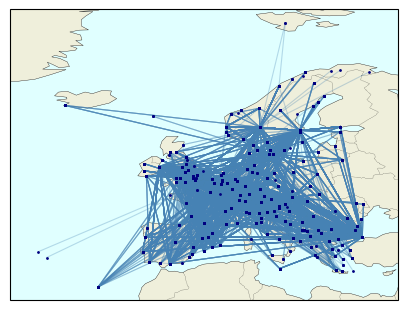

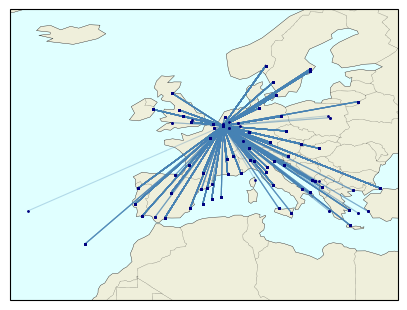

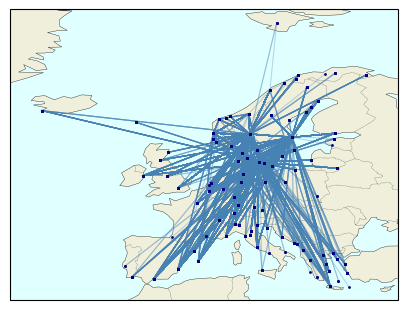

In [3]:
for name, rs in RS.items():
    ax = plot_flights_on_map(rs)
    if SAVE_FIGURES: save_figure(ax.figure, f"images/flights_{name}_trajectories", pad_inches=0.05)
    plt.show()

### 3. Quantile sets $K_\alpha$
Quantiles for 21 equally spaced levels $\alpha \in [0, 1]$.

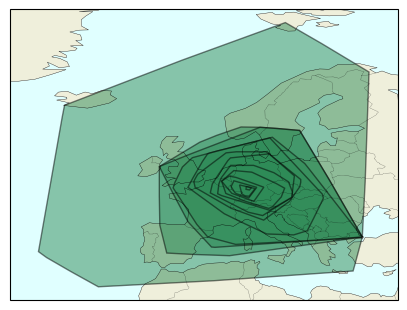

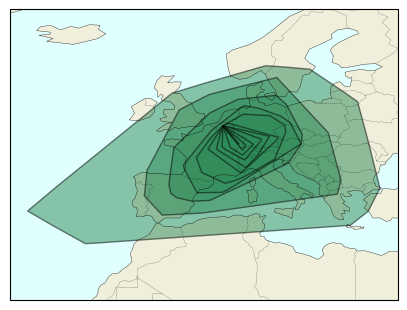

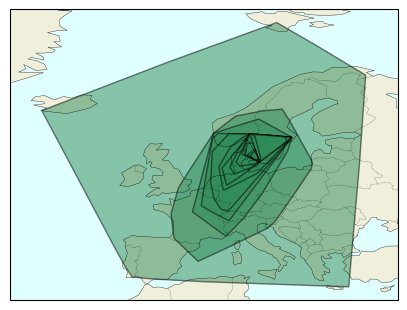

In [4]:
for name, rs in RS.items():
    ax = plot_quantiles_on_map(rs, alphas=np.linspace(0, 1, 21))
    if SAVE_FIGURES: save_figure(ax.figure, f"images/flights_{name}_quantiles", pad_inches=0.05)
    plt.show()

### 4. Bagplots

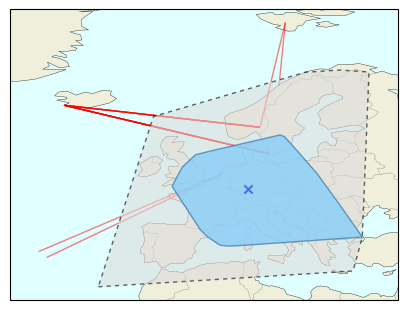

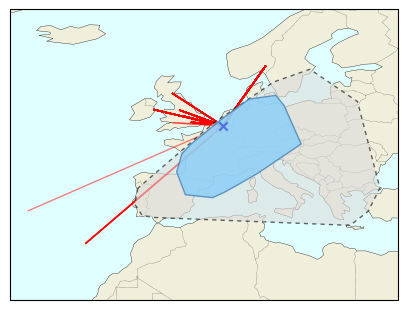

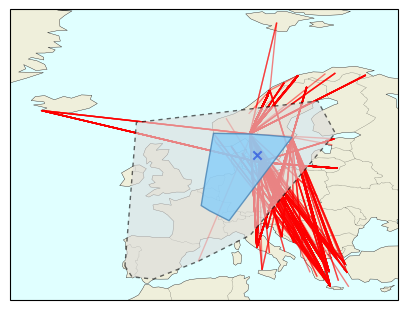

In [5]:
for name, rs in RS.items():
    ax = plot_flights_bagplot(rs)
    if SAVE_FIGURES: save_figure(ax.figure, f"images/flights_{name}_bagplot", pad_inches=0.05)
    plt.show()

### 5. Pairplots

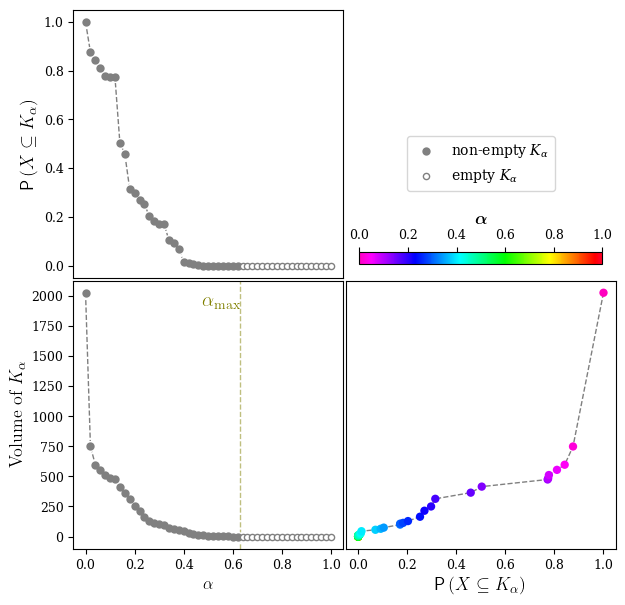

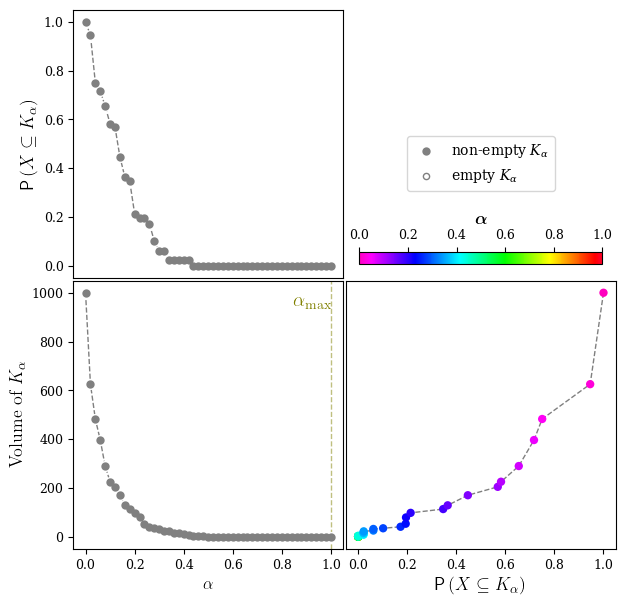

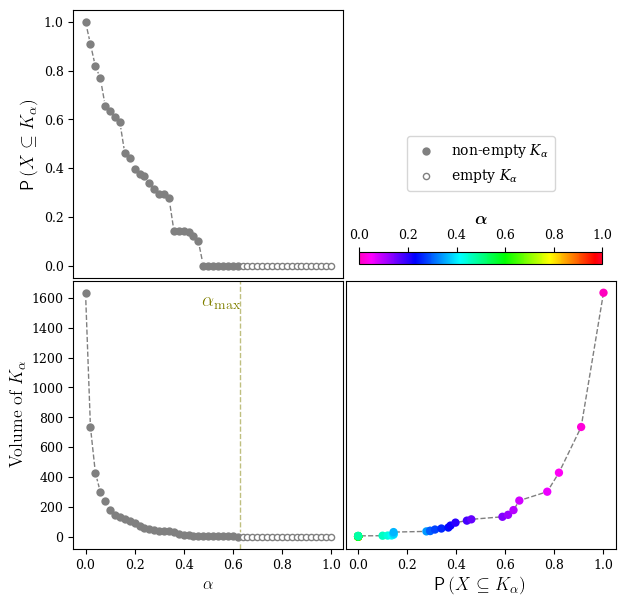

In [6]:
for name, rs in RS.items():
    fig, ax = rs.pairplot()
    if SAVE_FIGURES: save_figure(fig, f"images/flights_{name}_pairplot")
    plt.show()

### 6. Symmetry plots

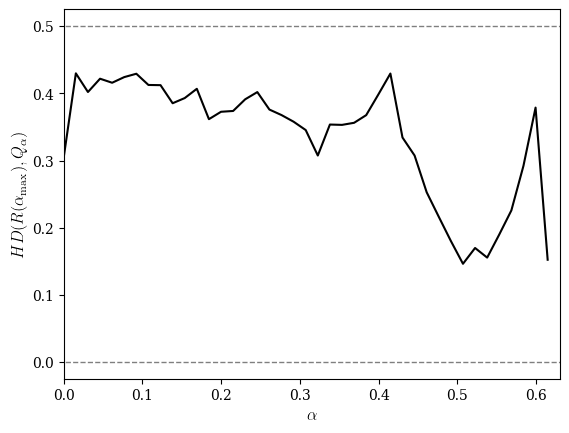

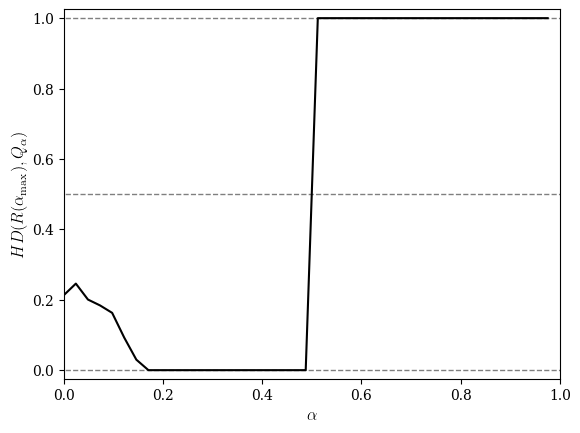

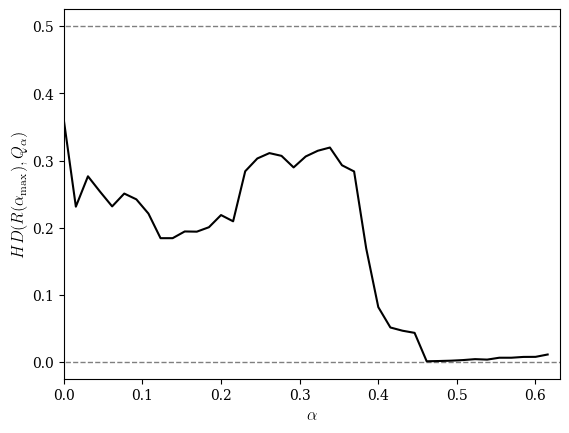

In [7]:
for name, rs in RS.items():
    ax = rs.symmetry_plot(seed=SEED)
    if SAVE_FIGURES: save_figure(ax.figure, f"images/flights_{name}_symmetry_plot", fig_size=(4, 4))
    plt.show()

### 7. Containment-capacity plots

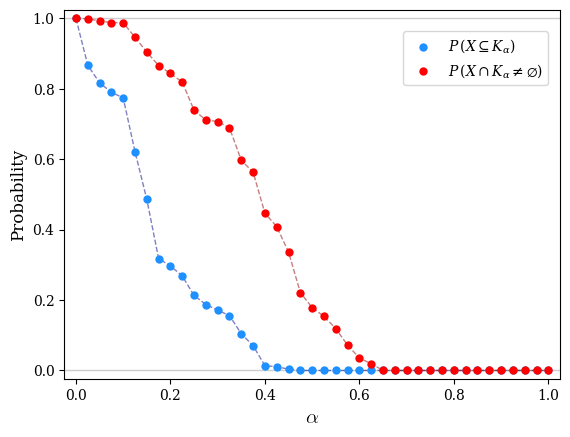

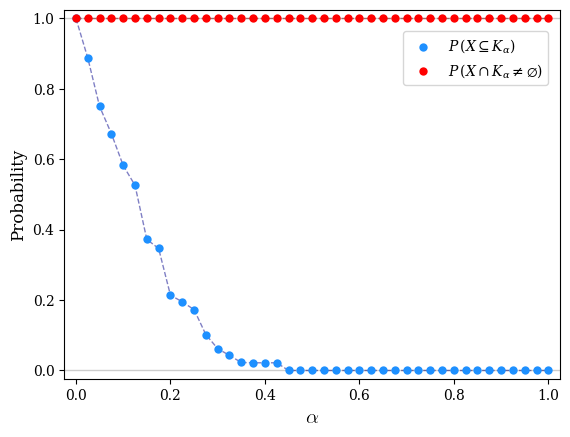

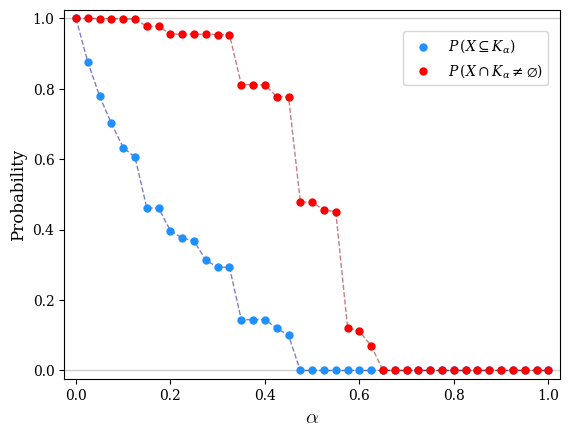

In [8]:
for name, rs in RS.items():
    ax = rs.containment_capacity_plot()
    if SAVE_FIGURES: save_figure(ax.figure, f"images/flights_{name}_CC_plot", fig_size=(4, 4))
    plt.show()